# Fase 1 — Pré-processamento dos Logs de Acesso Nginx

Este notebook implementa a **Fase 1** do pipeline de detecção de anomalias em logs de rede.  
O objetivo é transformar os arquivos de log brutos em um dataset limpo, estruturado e pronto para a engenharia de atributos (Fase 2).

### O que é feito aqui
1. **Parsing** - leitura de todos os arquivos de log da pasta `data/raw/` com regex robusta
2. **Inspeção inicial** - dimensões, tipos, valores nulos, exemplos
3. **Separação da requisição** - método HTTP, URI e versão do protocolo
4. **Limpeza** - remoção de colunas irrelevantes, tratamento de nulos, filtragem de IPs internos/loopback/privados
5. **Deduplicação** - remoção de registros 100% duplicados com justificativa
6. **Remoção de IP dominante** - tratamento de IPs de polling que distorcem modelos
7. **Persistência** - salva o resultado em `data/processed/logs_clean.parquet`

### Melhorias em relação ao TCC original (Erick)
| Problema original | Solução aqui |
|---|---|
| Conversão para CSV com lógica frágil de espaços | Regex direta no Combined Log Format |
| Loops `for i in range(N)` com `.at[i, col]` (horas de execução) | Operações vetorizadas (pandas/numpy) |
| Encoding que descartava informação (URI→3, método→1) | Colunas preservadas para a Fase 2 |
| Sem separação clara de treino/teste | Pipeline reproduzível com saída em Parquet |
| Arquivos CSV intermediários desnecessários | Parquet comprimido (~70% menor que CSV) |

---
**Estrutura de pastas esperada:**
```
projeto/
├── data/
│   ├── raw/          ← arquivos de log aqui (qualquer nome)
│   └── processed/    ← gerado automaticamente
├── notebooks/
│   ├── fase1_preprocessamento.ipynb
│   └── fase2_feature_engineering.ipynb   (próxima fase)
```

## 0. Dependências

In [3]:
import re
import ipaddress
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

print(f'pandas  : {pd.__version__}')
print(f'numpy   : {np.__version__}')

pandas  : 3.0.1
numpy   : 2.4.3


## 1. Configuração de Caminhos

In [5]:
# ── Ajuste aqui se necessário ──────────────────────────────────────────────────
RAW_DIR       = Path('../data/raw')        # pasta com os arquivos de log
PROCESSED_DIR = Path('../data/processed')  # pasta de saída (criada automaticamente)
OUTPUT_FILE   = PROCESSED_DIR / 'logs_clean.parquet'
# ──────────────────────────────────────────────────────────────────────────────

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Encontra todos os arquivos de log — cobre nomes comuns usados pelo Nginx
patterns = ['*.log', '*.log-*', 'access.*', '*access*', '*.txt']
seen = set()
log_files = []
for pat in patterns:
    for f in sorted(RAW_DIR.glob(pat)):
        if f not in seen and f.is_file():
            seen.add(f)
            log_files.append(f)

if not log_files:
    raise FileNotFoundError(
        f'Nenhum arquivo de log encontrado em "{RAW_DIR}".\n'
        f'Certifique-se de que os arquivos estão na pasta correta.'
    )

print(f'Arquivos encontrados em "{RAW_DIR}":')
for f in log_files:
    size_mb = f.stat().st_size / 1024 / 1024
    print(f'  {f.name:50s}  {size_mb:8.1f} MB')
print(f'\nTotal: {len(log_files)} arquivo(s)')

Arquivos encontrados em "..\data\raw":
  access.log-20230607                                     66.4 MB
  access.log-20230608                                     20.3 MB
  access.log-20230609                                    122.7 MB
  access.log-20230610                                    140.4 MB
  access.log-20230611                                    138.9 MB
  access.log-20230612                                     88.4 MB
  access.log-20230613                                    335.5 MB
  access.log-20230614                                    231.5 MB
  access.log-20230615                                    324.9 MB
  access.log-20230616                                    254.9 MB
  access.log-20230617                                    271.6 MB
  access.log-20230618                                    115.0 MB
  access.log-20230619                                     90.9 MB
  access.log-20230620                                    304.6 MB
  access.log-20230621                

## 2. Parser do Combined Log Format

O Nginx usa o **Combined Log Format** com um campo `$host` customizado no início:

```
$remote_addr - $remote_user [$time_local] $host "$request" $status $body_bytes_sent "$http_referer" "$http_user_agent" "$http_x_forwarded_for"
```

A regex cobre:
- IPs IPv4 e IPv6 (incluindo `::1`)
- Campos opcionais marcados com `-`
- Requisições malformadas (bytes não-ASCII, protocolos não-HTTP)
- Campo `x_forwarded_for` opcional

In [6]:
LOG_PATTERN = re.compile(
    r'(?P<ip>\S+)'                        # IP de origem (IPv4 ou IPv6)
    r' \S+'                               # ident (sempre '-', ignorado)
    r' (?P<remote_user>\S+)'              # remote_user
    r' \[(?P<time>[^\]]+)\]'             # [timestamp timezone]
    r' (?P<host>\S+)'                     # host requisitado (campo customizado)
    r' "(?P<request>[^"]*)"'             # "METHOD URI PROTOCOL"
    r' (?P<status>\d{3})'                 # HTTP status code
    r' (?P<bytes>\d+|-)'                  # bytes enviados
    r' "(?P<referer>[^"]*)"'             # HTTP Referer
    r' "(?P<user_agent>[^"]*)"'          # HTTP User-Agent
    r'(?:\s+"(?P<x_forwarded>[^"]*)")?' # X-Forwarded-For (opcional)
)

def parse_line(line: str) -> dict | None:
    """Parseia uma linha de log. Retorna dict com os campos ou None se inválida."""
    m = LOG_PATTERN.match(line.strip())
    if m is None:
        return None
    d = m.groupdict()
    # Normaliza '-' para None nos campos opcionais
    for key in ('remote_user', 'referer', 'user_agent', 'x_forwarded'):
        if d.get(key) in ('-', '', None):
            d[key] = None
    # '-' em bytes vira None
    if d['bytes'] == '-':
        d['bytes'] = None
    return d

# ── Teste do parser com linhas de exemplo ──────────────────────────────────────
test_lines = [
    '186.233.152.7 - - [06/Jun/2023:03:31:05 -0300] cdn.samsungcloudsolution.com "GET /Public/network/files/check.xml HTTP/1.1" 301 169 "-" "-" "-"',
    '40.77.167.196 - - [06/Jun/2023:03:31:05 -0300] www.coremu.uem.br "GET /processo-seletivo/2016 HTTP/1.1" 200 4409 "-" "Mozilla/5.0 (compatible; bingbot/2.0)" "-"',
    '::1 - - [06/Jun/2023:03:31:07 -0300] localhost "GET /basic_status HTTP/1.1" 200 121 "-" "collectd/5.8.1" "-"',
    '37.139.53.80 - - [06/Jun/2023:03:31:30 -0300] www.dfe.uem.br "GET /path/ HTTP/1.0" 200 65148 "http://ref.uem.br/" "Mozilla/5.0 (Windows NT 6.1)" "-"',
]
print('=== Teste do parser ===')
for line in test_lines:
    r = parse_line(line)
    if r:
        print(f'  ip={r["ip"]}  host={r["host"]}  status={r["status"]}  method_in_req={r["request"][:20]}...')
    else:
        print(f'  FALHA: {line[:60]}')
print('\nParser funcionando corretamente.')

=== Teste do parser ===
  ip=186.233.152.7  host=cdn.samsungcloudsolution.com  status=301  method_in_req=GET /Public/network/...
  ip=40.77.167.196  host=www.coremu.uem.br  status=200  method_in_req=GET /processo-seleti...
  ip=::1  host=localhost  status=200  method_in_req=GET /basic_status HT...
  ip=37.139.53.80  host=www.dfe.uem.br  status=200  method_in_req=GET /path/ HTTP/1.0...

Parser funcionando corretamente.


## 3. Leitura de Todos os Arquivos

In [7]:
records  = []
file_stats = {}

for fpath in log_files:
    total = parsed = failed = 0

    with open(fpath, 'r', encoding='utf-8', errors='replace') as f:
        for line in f:
            if not line.strip():
                continue
            total += 1
            result = parse_line(line)
            if result is not None:
                result['source_file'] = fpath.name  # rastreabilidade
                records.append(result)
                parsed += 1
            else:
                failed += 1

    file_stats[fpath.name] = {'total': total, 'parsed': parsed, 'failed': failed}
    fail_pct = failed / total * 100 if total > 0 else 0
    print(f'{fpath.name:50s}  total={total:>9,}  ok={parsed:>9,}  falhas={failed:>6,} ({fail_pct:.1f}%)')

print(f'\n{"─"*60}')
print(f'Total de registros parseados: {len(records):,}')

access.log-20230607                                 total=  233,384  ok=  233,383  falhas=     1 (0.0%)
access.log-20230608                                 total=   75,279  ok=   75,278  falhas=     1 (0.0%)
access.log-20230609                                 total=  451,152  ok=  451,152  falhas=     0 (0.0%)
access.log-20230610                                 total=  492,997  ok=  492,997  falhas=     0 (0.0%)
access.log-20230611                                 total=  445,837  ok=  445,837  falhas=     0 (0.0%)
access.log-20230612                                 total=  324,859  ok=  324,859  falhas=     0 (0.0%)
access.log-20230613                                 total=1,180,085  ok=1,180,085  falhas=     0 (0.0%)
access.log-20230614                                 total=  821,324  ok=  821,322  falhas=     2 (0.0%)
access.log-20230615                                 total=1,108,116  ok=1,108,099  falhas=    17 (0.0%)
access.log-20230616                                 total=  913,

In [ ]:
# Monta o DataFrame principal
df_raw = pd.DataFrame(records)

# Converte tipos numéricos
df_raw['status'] = pd.to_numeric(df_raw['status'], errors='coerce').astype('Int16')
df_raw['bytes']  = pd.to_numeric(df_raw['bytes'],  errors='coerce').astype('Int64')

# Parse do timestamp — formato: '06/Jun/2023:03:31:05 -0300'
df_raw['timestamp'] = pd.to_datetime(
    df_raw['time'], format='%d/%b/%Y:%H:%M:%S %z', utc=True, errors='coerce'
)

print(f'Shape inicial   : {df_raw.shape}')
print(f'Colunas         : {df_raw.columns.tolist()}')
print(f'Período dos logs: {df_raw["timestamp"].min()} → {df_raw["timestamp"].max()}')
print()
df_raw.head(3)

Shape inicial   : (10232270, 12)
Colunas         : ['ip', 'remote_user', 'time', 'host', 'request', 'status', 'bytes', 'referer', 'user_agent', 'x_forwarded', 'source_file', 'timestamp']
Período dos logs: 2023-06-06 06:31:05+00:00 → 2023-06-21 06:31:16+00:00



,ip,remote_user,time,host,request,status,bytes,referer,user_agent,x_forwarded,source_file,timestamp
0,186.233.152.7,NaN,06/Jun/2023:03:31:05 -0300,cdn.samsungcloudsolution.com,GET /Public/network/files/check.xml HTTP/1.1,301,169,NaN,NaN,NaN,access.log-20230607,2023-06-06 06:31:05+00:00
1,40.77.167.196,NaN,06/Jun/2023:03:31:05 -0300,www.coremu.uem.br,GET /processo-seletivo/2016/residencia-em-odon...,200,4409,NaN,"Mozilla/5.0 AppleWebKit/537.36 (KHTML, like Ge...",NaN,access.log-20230607,2023-06-06 06:31:05+00:00
2,186.233.152.7,NaN,06/Jun/2023:03:31:07 -0300,cdn.samsungcloudsolution.com,GET /Public/network/files/check.xml HTTP/1.1,301,169,NaN,NaN,NaN,access.log-20230607,2023-06-06 06:31:07+00:00


## 4. Inspeção Inicial

In [9]:
print('=== Informações gerais ===')
df_raw.info(verbose=True, show_counts=True)

=== Informações gerais ===
<class 'pandas.DataFrame'>
RangeIndex: 10232270 entries, 0 to 10232269
Data columns (total 12 columns):
 #   Column       Non-Null Count     Dtype              
---  ------       --------------     -----              
 0   ip           10232270 non-null  str                
 1   remote_user  1407 non-null      str                
 2   time         10232270 non-null  str                
 3   host         10232270 non-null  str                
 4   request      10232270 non-null  str                
 5   status       10232270 non-null  Int16              
 6   bytes        10232270 non-null  Int64              
 7   referer      2112671 non-null   str                
 8   user_agent   3194398 non-null   str                
 9   x_forwarded  31016 non-null     str                
 10  source_file  10232270 non-null  str                
 11  timestamp    10232270 non-null  datetime64[us, UTC]
dtypes: Int16(1), Int64(1), datetime64[us, UTC](1), str(9)
memory usage

In [10]:
print('=== Valores nulos por coluna ===')
null_counts = df_raw.isnull().sum()
null_pct    = (null_counts / len(df_raw) * 100).round(2)
display(
    pd.DataFrame({'nulos': null_counts, '%': null_pct})
    .query('nulos > 0')
    .sort_values('nulos', ascending=False)
)

=== Valores nulos por coluna ===


,nulos,%
remote_user,10230863,99.99
x_forwarded,10201254,99.70
referer,8119599,79.35
user_agent,7037872,68.78


In [11]:
print('=== Distribuição de Status HTTP (top 20) ===')
display(df_raw['status'].value_counts().head(20))

print('\n=== Top 10 IPs por volume ===')
display(df_raw['ip'].value_counts().head(10))

print('\n=== Top 10 Hosts requisitados ===')
display(df_raw['host'].value_counts().head(10))

=== Distribuição de Status HTTP (top 20) ===


status
400    6415871
200    2397556
301     990948
404     379933
304      23586
302      11116
409       5900
206       2534
500       2255
499       1951
503        184
401        126
429         67
303         47
405         47
403         34
414         32
408         27
307         15
504         15
Name: count, dtype: Int64


=== Top 10 IPs por volume ===


ip
186.233.152.7      7418716
::1                 111651
43.131.49.250        67289
139.18.2.214         36728
216.244.66.235       29031
40.77.167.196        25626
198.71.236.20        23687
40.77.167.107        21662
45.71.104.191        20518
186.233.190.218      20497
Name: count, dtype: int64


=== Top 10 Hosts requisitados ===


host
_                               6415965
www.uem.br                       902179
cdn.samsungcloudsolution.com     608895
www.daa.uem.br                   354381
sites.uem.br                     260915
c.whatsapp.net                   157933
www.dfe.uem.br                   129898
localhost                        111653
www.prh.uem.br                    79788
www.dhi.uem.br                    74089
Name: count, dtype: int64

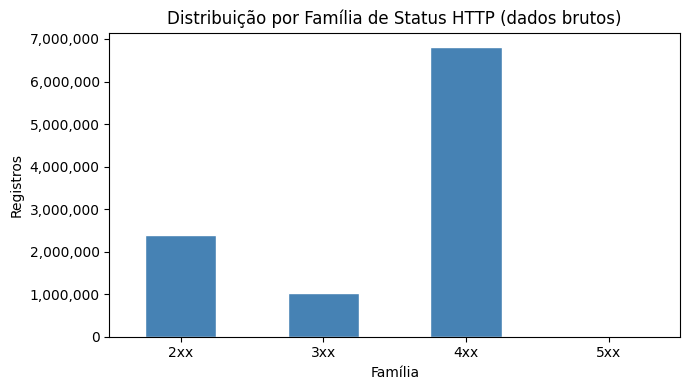

In [24]:
fig, ax = plt.subplots(figsize=(7, 4))

status_family = (df_raw['status'].dropna() // 100).astype(int).astype(str).add('xx')
status_family.value_counts().sort_index().plot.bar(
    ax=ax, color='steelblue', edgecolor='white'
)

ax.set_title('Distribuição por Família de Status HTTP (dados brutos)')
ax.set_xlabel('Família')
ax.set_ylabel('Registros')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fase1fig1_distribuicao_status_http(bruto).png', dpi=120, bbox_inches='tight')
plt.show()
plt.close(fig)  # Fecha a figura para liberar memória

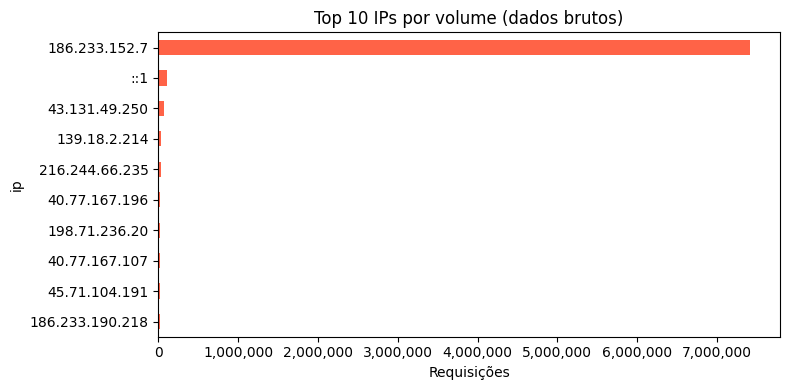

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))

df_raw['ip'].value_counts().head(10).plot.barh(
    ax=ax, color='tomato'
)

ax.set_title('Top 10 IPs por volume (dados brutos)')
ax.set_xlabel('Requisições')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.invert_yaxis()

plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fase1fig2_top_ips(bruto).png', dpi=120, bbox_inches='tight')
plt.show()
plt.close(fig)

## 5. Separação da Coluna `request`

O campo `request` (ex: `"GET /path HTTP/1.1"`) é separado em três colunas:

| Coluna nova | Exemplo | Observação |
|---|---|---|
| `http_method` | `GET`, `POST` | `MALFORMED` se não segue o padrão |
| `uri` | `/path?q=1` | Preservada integralmente para análise na Fase 2 |
| `http_version` | `HTTP/1.1` | `UNKNOWN` se não identificada |

In [25]:
REQUEST_PATTERN = re.compile(
    r'^(?P<method>[A-Z]{2,10})\s+(?P<uri>\S+)\s+(?P<version>HTTP/[\d.]+)$'
)

VALID_METHODS = frozenset({
    'GET', 'POST', 'PUT', 'DELETE', 'HEAD',
    'OPTIONS', 'PATCH', 'CONNECT', 'TRACE'
})

def split_request(req) -> tuple:
    """Divide a string de requisição em (método, uri, versão).
    Requisições malformadas têm o conteúdo original preservado na URI
    para análise posterior na Fase 2 (detecção de ataques).
    """
    if not isinstance(req, str) or not req.strip():
        return ('MISSING', '', 'UNKNOWN')
    m = REQUEST_PATTERN.match(req.strip())
    if m:
        method  = m.group('method')
        uri     = m.group('uri')
        version = m.group('version')
        if method not in VALID_METHODS:
            method = 'OTHER_METHOD'
        return (method, uri, version)
    # Malformada: preserva conteúdo original na URI para análise
    return ('MALFORMED', req, 'UNKNOWN')

# Aplica via apply — vetorizado a nível de série, sem loop Python explícito
parsed = df_raw['request'].apply(split_request)
df_raw[['http_method', 'uri', 'http_version']] = pd.DataFrame(
    parsed.tolist(), index=df_raw.index
)

print('=== Distribuição de Métodos HTTP ===')
display(df_raw['http_method'].value_counts())

print('\n=== Distribuição de Versões HTTP ===')
display(df_raw['http_version'].value_counts())

=== Distribuição de Métodos HTTP ===


http_method
MALFORMED       6350212
GET             3625643
POST             183298
CONNECT           64019
HEAD               7752
MISSING             983
PUT                 245
OTHER_METHOD         83
OPTIONS              27
PATCH                 8
Name: count, dtype: int64


=== Distribuição de Versões HTTP ===


http_version
UNKNOWN     6351195
HTTP/1.1    3821064
HTTP/1.0      59938
HTTP/2.0         70
HTTP/1.9          3
Name: count, dtype: int64

In [11]:
malformed = df_raw[df_raw['http_method'] == 'MALFORMED']
n_malformed = len(malformed)
print(f'Requisições MALFORMED: {n_malformed:,} ({n_malformed / len(df_raw) * 100:.3f}% do total)')
print('\nExemplos de requisições malformadas (primeiros 8):')
display(
    malformed[['ip', 'host', 'uri', 'status', 'bytes']]
    .head(8)
    .assign(uri=lambda d: d['uri'].str[:60])  # trunca para exibição
)

Requisições MALFORMED: 6,350,212 (62.061% do total)

Exemplos de requisições malformadas (primeiros 8):


,ip,host,uri,status,bytes
309,186.233.152.7,_,\x16\x03\x01\x022\x01\x00\x02.\x03\x03OT)\x06\...,400,157
417,186.233.152.7,_,\x16\x03\x01\x02/\x01\x00\x02+\x03\x03\xA1\x0F...,400,157
418,186.233.152.7,_,\x16\x03\x01\x01\x91\x01\x00\x01\x8D\x03\x03\x...,400,157
419,186.233.152.7,_,\x16\x03\x01\x02/\x01\x00\x02+\x03\x03\xD7\x90...,400,157
420,186.233.152.7,_,\x16\x03\x01\x02\x00\x01\x00\x01\xFC\x03\x03\x...,400,157
421,186.233.152.7,_,\x16\x03\x01\x00\xE0\x01\x00\x00\xDC\x03\x03\x...,400,157
424,186.233.152.7,_,\x16\x03\x01\x02/\x01\x00\x02+\x03\x03\xD3\xC7...,400,157
425,186.233.152.7,_,\x16\x03\x01\x02/\x01\x00\x02+\x03\x03\xE2:\xD...,400,157


## 6. Limpeza

### 6.1 — Remoção de Colunas Desnecessárias

| Coluna | Motivo da remoção |
|---|---|
| `time` (string original) | Substituída por `timestamp` (datetime com timezone) |
| `request` (string original) | Substituída pelas colunas `http_method`, `uri`, `http_version` |

In [12]:
df = df_raw.drop(columns=['time', 'request']).copy()
print(f'Colunas após remoção: {df.columns.tolist()}')
print(f'Shape: {df.shape}')

Colunas após remoção: ['ip', 'remote_user', 'host', 'status', 'bytes', 'referer', 'user_agent', 'x_forwarded', 'source_file', 'timestamp', 'http_method', 'uri', 'http_version']
Shape: (10232270, 13)


### 6.2 — Remoção de IPs de Loopback e Registros de Monitoramento Interno

`::1` e `127.0.0.1` são acessos locais do próprio servidor (ex: `collectd` checando `/basic_status`). Não representam tráfego externo e seriam ruído nos modelos.

In [13]:
LOOPBACK_IPS    = {'::1', '127.0.0.1'}
INTERNAL_HOSTS  = {'localhost', '_'}  # '_' aparece em requisições sem SNI

mask_internal = df['ip'].isin(LOOPBACK_IPS) | df['host'].isin(INTERNAL_HOSTS)
n_removed     = mask_internal.sum()

print(f'Hosts internos encontrados: {df[mask_internal]["host"].value_counts().to_dict()}')
print(f'Registros removidos       : {n_removed:,}')

df = df[~mask_internal].copy()
print(f'Shape após remoção        : {df.shape}')

Hosts internos encontrados: {'_': 6415965, 'localhost': 111653}
Registros removidos       : 6,527,618
Shape após remoção        : (3704652, 13)


### 6.3 — Remoção de IPs Privados (RFC 1918)

IPs de redes internas não são origem externa. Incluí-los misturaria tráfego interno (com padrões próprios) com o externo.

In [14]:
PRIVATE_NETWORKS = [
    ipaddress.ip_network('10.0.0.0/8'),
    ipaddress.ip_network('172.16.0.0/12'),
    ipaddress.ip_network('192.168.0.0/16'),
]

def is_private_ip(ip_str: str) -> bool:
    try:
        addr = ipaddress.ip_address(ip_str)
        return any(addr in net for net in PRIVATE_NETWORKS)
    except ValueError:
        return False

# Processa apenas IPs únicos para evitar recalcular o mesmo IP milhões de vezes
unique_ips   = df['ip'].unique()
private_set  = {ip for ip in unique_ips if is_private_ip(ip)}

mask_private = df['ip'].isin(private_set)
n_private    = mask_private.sum()

print(f'IPs privados únicos: {len(private_set):,}')
print(f'Registros removidos: {n_private:,}')

df = df[~mask_private].copy()
print(f'Shape após remoção : {df.shape}')

IPs privados únicos: 2,182
Registros removidos: 250,945
Shape após remoção : (3453707, 13)


### 6.4 — Tratamento de Valores Nulos

**Política de nulos:**

| Coluna | Nulo significa | Ação |
|---|---|---|
| `status`, `bytes`, `timestamp` | Falha no parsing — linha corrompida | Descarta a linha |
| `remote_user` | Sem autenticação HTTP (normal) | Preenche com `'-'` |
| `referer` | Acesso direto sem referência (normal) | Preenche com `'-'` |
| `user_agent` | UA ausente (pode ser suspeito) | Preenche com `'-'` |
| `x_forwarded` | Sem proxy (normal) | Preenche com `'-'` |
| `uri` | Só para MISSING/MALFORMED | Preenche com string vazia |

In [15]:
# Descarta linhas com campos críticos ausentes
n_before = len(df)
df = df.dropna(subset=['status', 'bytes', 'timestamp'])
n_dropped = n_before - len(df)
print(f'Linhas descartadas (campos críticos nulos): {n_dropped:,}')

# Preenche campos opcionais com '-'
for col in ['remote_user', 'referer', 'user_agent', 'x_forwarded']:
    if col in df.columns:
        df[col] = df[col].fillna('-')

df['uri'] = df['uri'].fillna('')

print('\nNulos restantes:')
remaining_nulls = df.isnull().sum()
remaining_nulls = remaining_nulls[remaining_nulls > 0]
if remaining_nulls.empty:
    print('  Nenhum nulo restante.')
else:
    display(remaining_nulls)

print(f'\nShape após tratamento de nulos: {df.shape}')

Linhas descartadas (campos críticos nulos): 0

Nulos restantes:
  Nenhum nulo restante.

Shape após tratamento de nulos: (3453707, 13)


### 6.5 — Deduplicação

**Critério:** Registros com mesmo IP, timestamp, host, método, URI, status e bytes são artefatos do sistema de log (mesmo acesso registrado duas vezes).

**Distinção importante:** Não removemos registros com mesmo conteúdo mas timestamps diferentes — isso seria legítimo (usuário acessando a mesma página duas vezes).

In [16]:
DEDUP_SUBSET = ['ip', 'timestamp', 'host', 'http_method', 'uri', 'status', 'bytes']

n_before = len(df)
df = df.drop_duplicates(subset=DEDUP_SUBSET, keep='first')
n_dupes  = n_before - len(df)

print(f'Duplicatas removidas: {n_dupes:,}  ({n_dupes / n_before * 100:.1f}% dos registros)')
print(f'Shape após dedup    : {df.shape}')

Duplicatas removidas: 165,645  (4.8% dos registros)
Shape após dedup    : (3288062, 13)


### 6.6 — Análise e Remoção do IP Dominante

Um IP que concentra grande parte do tráfego distorce qualquer modelo de detecção de anomalias: cria um **viés de normalização** que afasta todos os demais registros do centro da distribuição, como descrito no TCC original (Erick, 2023).

**O caso concreto deste dataset:** o IP `186.233.152.7` pertence a um dispositivo Wi-Fi da própria universidade (UEM) que realiza checagens de conectividade periódicas. Antes da remoção dos hosts internos (`_`, `localhost`), esse IP representava ~72% de todo o tráfego. Após essa filtragem, o volume cai para ~28%, mas o impacto ainda é significativo.

**Por que o critério de URIs únicas falhou?** Após remover os hosts `_`, o IP ainda tem registros variados (CONNECT, TLS malformado, requisições para múltiplos hosts). O critério correto deve ser avaliado no **tráfego bruto** — antes de qualquer filtro — que é onde o viés se origina.

**Critério adotado (dois estágios):**
1. Avalia concentração no dataset **bruto** original (antes de qualquer limpeza)
2. Remove se representava > 50% do bruto **OU** ainda representa > 20% do limpo com razão volume/diversidade > 100 (muitas requisições, baixa diversidade relativa)

In [17]:
ip_counts = df['ip'].value_counts()
total     = len(df)

# Concentração no dataset BRUTO (antes de qualquer filtro)
# É aqui que o viés se origina — o IP pode ter sido 'diluído' pela limpeza
ip_counts_raw = pd.Series([r['ip'] for r in records]).value_counts()
total_raw     = len(records)

print('Top 10 IPs após limpeza:')
top_10 = ip_counts.head(10).reset_index()
top_10.columns = ['ip', 'count']
top_10['% limpo'] = (top_10['count'] / total * 100).round(2)
top_10['% bruto'] = top_10['ip'].map(
    lambda ip: round(ip_counts_raw.get(ip, 0) / total_raw * 100, 2)
)
display(top_10)

# Razão volume/diversidade: quantas requisições por URI única
# Alto valor = comportamento repetitivo (polling/bot uniforme)
print('\nDiversidade de comportamento (top 5):')
print(f'  {"IP":<22} {"req":>9} {"URIs únicas":>12} {"req/URI":>8} {"% bruto":>8}')
print('  ' + '─'*65)
for ip in ip_counts.head(5).index:
    ip_data    = df[df['ip'] == ip]
    n_req      = len(ip_data)
    n_uris     = ip_data['uri'].nunique()
    ratio      = n_req / max(n_uris, 1)
    pct_bruto  = ip_counts_raw.get(ip, 0) / total_raw * 100
    print(f'  {ip:<22} {n_req:>9,} {n_uris:>12,} {ratio:>8.1f} {pct_bruto:>7.1f}%')

Top 10 IPs após limpeza:


,ip,count,% limpo,% bruto
0,186.233.152.7,932584,28.36,72.50
1,139.18.2.214,36728,1.12,0.36
2,216.244.66.235,28751,0.87,0.28
3,40.77.167.196,25595,0.78,0.25
4,40.77.167.107,21640,0.66,0.21
5,45.71.104.191,20515,0.62,0.20
6,186.233.190.218,20494,0.62,0.20
7,198.71.236.20,18410,0.56,0.23
8,40.77.167.208,17404,0.53,0.17
9,65.108.99.49,16077,0.49,0.16



Diversidade de comportamento (top 5):
  IP                           req  URIs únicas  req/URI  % bruto
  ─────────────────────────────────────────────────────────────────
  186.233.152.7            932,584        5,080    183.6    72.5%
  139.18.2.214              36,728       35,237      1.0     0.4%
  216.244.66.235            28,751       19,973      1.4     0.3%
  40.77.167.196             25,595       14,888      1.7     0.3%
  40.77.167.107             21,640       13,145      1.6     0.2%


In [18]:
# ── Thresholds (ajuste conforme o dataset) ────────────────────────────────────
BRUTO_THRESHOLD = 0.50   # > 50% no bruto → remoção direta (viés grave)
LIMPO_THRESHOLD = 0.20   # > 20% no limpo (estágio 2)
RATIO_THRESHOLD = 50     # req/URI > 50 no limpo (estágio 2 — comportamento repetitivo)

# ── Pré-computa todas as estatísticas de uma vez — sem loop por IP ─────────────
# URIs únicas por IP: groupby é O(N) uma única vez
uris_por_ip = df.groupby('ip')['uri'].nunique().rename('n_uris')

# Monta tabela de análise com operações vetorizadas
ip_stats = pd.DataFrame({
    'count_limpo': ip_counts,
    'n_uris'     : uris_por_ip,
})
ip_stats['pct_limpo'] = ip_stats['count_limpo'] / total
ip_stats['pct_bruto'] = ip_stats.index.map(
    lambda ip: ip_counts_raw.get(ip, 0) / total_raw
)
ip_stats['ratio']     = ip_stats['count_limpo'] / ip_stats['n_uris'].clip(lower=1)

print('Top 10 IPs — estatísticas de dominância:')
display(
    ip_stats.head(10)
    .assign(
        pct_limpo=lambda d: (d['pct_limpo']*100).round(2),
        pct_bruto=lambda d: (d['pct_bruto']*100).round(2),
        ratio    =lambda d: d['ratio'].round(1),
    )
)

# ── Aplica critérios vetorizados ───────────────────────────────────────────────
mask_estagio1 = ip_stats['pct_bruto'] > BRUTO_THRESHOLD
mask_estagio2 = (ip_stats['pct_limpo'] > LIMPO_THRESHOLD) & (ip_stats['ratio'] > RATIO_THRESHOLD)

dominant_ips_removed = ip_stats[mask_estagio1 | mask_estagio2].index.tolist()

for ip in dominant_ips_removed:
    row    = ip_stats.loc[ip]
    motivo = 'Estágio 1 — viés bruto' if mask_estagio1.get(ip, False) else 'Estágio 2 — repetitivo'
    print(
        f'[{motivo}] {ip}\n'
        f'  % bruto: {row["pct_bruto"]*100:.1f}%  '
        f'% limpo: {row["pct_limpo"]*100:.1f}%  '
        f'req/URI: {row["ratio"]:.0f}'
    )

if not dominant_ips_removed:
    top     = ip_stats.iloc[0]
    top_ip  = ip_stats.index[0]
    print('Nenhum IP atende aos critérios de remoção automática.')
    print(f'  IP mais frequente: {top_ip}  '
          f'% bruto: {top["pct_bruto"]*100:.1f}%  '
          f'% limpo: {top["pct_limpo"]*100:.1f}%')

Top 10 IPs — estatísticas de dominância:


,count_limpo,n_uris,pct_limpo,pct_bruto,ratio
ip,,,,,
1.116.84.14,14,12,0.0,0.0,1.2
1.117.241.78,20,20,0.0,0.0,1.0
1.117.80.180,2,2,0.0,0.0,1.0
1.12.247.125,9,1,0.0,0.0,9.0
1.12.253.254,4,1,0.0,0.0,4.0
1.12.54.191,4,1,0.0,0.0,4.0
1.12.75.127,6,1,0.0,0.0,6.0
1.13.9.65,3,3,0.0,0.0,1.0
1.169.103.19,52,6,0.0,0.0,8.7


[Estágio 1 — viés bruto] 186.233.152.7
  % bruto: 72.5%  % limpo: 28.4%  req/URI: 184


In [19]:
n_before = len(df)

if dominant_ips_removed:
    df = df[~df['ip'].isin(dominant_ips_removed)].copy()
    print(f'Registros removidos: {n_before - len(df):,}')
else:
    print('Nenhum IP removido nesta etapa.')

df = df.reset_index(drop=True)
print(f'Shape final       : {df.shape}')

Registros removidos: 932,584
Shape final       : (2355478, 13)


## 7. Visão Geral do Dataset Limpo

In [20]:
print('=== Dataset limpo — informações finais ===')
df.info(verbose=True, show_counts=True)

=== Dataset limpo — informações finais ===
<class 'pandas.DataFrame'>
RangeIndex: 2355478 entries, 0 to 2355477
Data columns (total 13 columns):
 #   Column        Non-Null Count    Dtype              
---  ------        --------------    -----              
 0   ip            2355478 non-null  str                
 1   remote_user   2355478 non-null  str                
 2   host          2355478 non-null  str                
 3   status        2355478 non-null  Int16              
 4   bytes         2355478 non-null  Int64              
 5   referer       2355478 non-null  str                
 6   user_agent    2355478 non-null  str                
 7   x_forwarded   2355478 non-null  str                
 8   source_file   2355478 non-null  str                
 9   timestamp     2355478 non-null  datetime64[us, UTC]
 10  http_method   2355478 non-null  str                
 11  uri           2355478 non-null  str                
 12  http_version  2355478 non-null  str                


In [21]:
print('=== Estatísticas descritivas ===')
display(df[['status', 'bytes']].describe())

=== Estatísticas descritivas ===


,status,bytes
count,2355478.0,2355478.0
mean,233.427247,83067.793627
std,73.393194,597020.224009
min,200.0,0.0
25%,200.0,1038.0
50%,200.0,7561.0
75%,200.0,27771.0
max,504.0,150794874.0


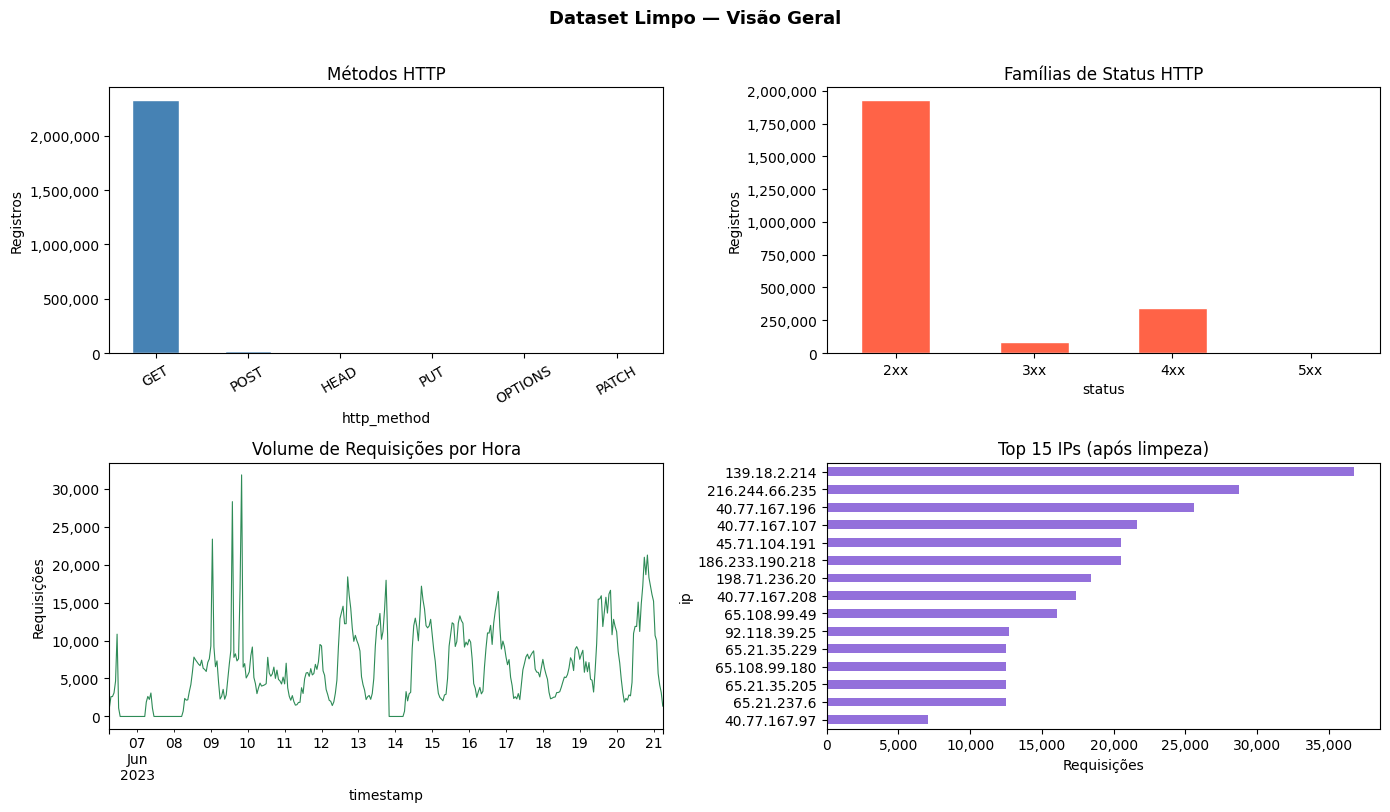

Gráfico salvo em data/processed/fig_02_dataset_limpo.png


In [22]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Distribuição de métodos HTTP
df['http_method'].value_counts().plot.bar(
    ax=axes[0, 0], color='steelblue', edgecolor='white'
)
axes[0, 0].set_title('Métodos HTTP')
axes[0, 0].set_ylabel('Registros')
axes[0, 0].tick_params(axis='x', rotation=30)
axes[0, 0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Famílias de status HTTP
status_fam = (df['status'] // 100).astype(int).astype(str).add('xx')
status_fam.value_counts().sort_index().plot.bar(
    ax=axes[0, 1], color='tomato', edgecolor='white'
)
axes[0, 1].set_title('Famílias de Status HTTP')
axes[0, 1].set_ylabel('Registros')
axes[0, 1].tick_params(axis='x', rotation=0)
axes[0, 1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Volume ao longo do tempo (por hora)
try:
    df.set_index('timestamp').resample('1h')['ip'].count().plot(
        ax=axes[1, 0], color='seagreen', linewidth=0.8
    )
    axes[1, 0].set_title('Volume de Requisições por Hora')
    axes[1, 0].set_ylabel('Requisições')
    axes[1, 0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
except Exception as e:
    axes[1, 0].text(0.5, 0.5, str(e), ha='center', va='center', transform=axes[1, 0].transAxes)

# Top 15 IPs restantes
df['ip'].value_counts().head(15).plot.barh(
    ax=axes[1, 1], color='mediumpurple'
)
axes[1, 1].set_title('Top 15 IPs (após limpeza)')
axes[1, 1].set_xlabel('Requisições')
axes[1, 1].invert_yaxis()
axes[1, 1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

plt.suptitle('Dataset Limpo — Visão Geral', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_02_dataset_limpo.png', dpi=120, bbox_inches='tight')
plt.show()
print('Gráfico salvo em data/processed/fig_02_dataset_limpo.png')

In [23]:
print('=== Amostra do dataset limpo ===')
display(
    df[['ip', 'timestamp', 'host', 'http_method',
        'uri', 'http_version', 'status', 'bytes', 'user_agent']]
    .head(10)
)

=== Amostra do dataset limpo ===


,ip,timestamp,host,http_method,uri,http_version,status,bytes,user_agent
0,40.77.167.196,2023-06-06 06:31:05+00:00,www.coremu.uem.br,GET,/processo-seletivo/2016/residencia-em-odontolo...,HTTP/1.1,200,4409,"Mozilla/5.0 AppleWebKit/537.36 (KHTML, like Ge..."
1,213.180.203.56,2023-06-06 06:31:09+00:00,www.dfe.uem.br,GET,/comunicauem/2017/11/10/por-que-a-uem-nao-tem-...,HTTP/1.1,200,15300,Mozilla/5.0 (compatible; YandexBot/3.0; +http:...
2,40.77.167.85,2023-06-06 06:31:16+00:00,www.dma.uem.br,GET,/robots.txt,HTTP/1.1,200,451,"Mozilla/5.0 AppleWebKit/537.36 (KHTML, like Ge..."
3,157.55.39.211,2023-06-06 06:31:29+00:00,www.pbf.uem.br,GET,/arquivos/files/ficha-inscricao-nao-regular-a-...,HTTP/1.1,200,133677,"Mozilla/5.0 AppleWebKit/537.36 (KHTML, like Ge..."
4,37.139.53.80,2023-06-06 06:31:30+00:00,www.dfe.uem.br,GET,/comunicauem/2017/06/05/as-minas-da-cataclisma/,HTTP/1.0,200,65148,Mozilla/5.0 (Windows NT 6.1; Win64; x64) Apple...
5,37.139.53.80,2023-06-06 06:31:31+00:00,www.dfe.uem.br,POST,/comunicauem/wp-comments-post.php,HTTP/1.0,499,0,Mozilla/5.0 (Windows NT 6.1; Win64; x64) Apple...
6,40.77.167.196,2023-06-06 06:31:47+00:00,www.det.uem.br,GET,/pmu/regulamentacao/pdfs/resolucao_042_2022_pm...,HTTP/1.1,200,137363,"Mozilla/5.0 AppleWebKit/537.36 (KHTML, like Ge..."
7,40.77.167.107,2023-06-06 06:31:54+00:00,www.csa.uem.br,GET,/normas-e-legislacao/resolucoes/resolucoes-201...,HTTP/1.1,200,14493,"Mozilla/5.0 AppleWebKit/537.36 (KHTML, like Ge..."
8,141.94.106.127,2023-06-06 06:31:55+00:00,dpi.uem.br,GET,/robots.txt,HTTP/1.1,301,169,Mozilla/5.0 (compatible; SeekportBot; +https:/...
9,141.94.106.127,2023-06-06 06:31:56+00:00,dpi.uem.br,GET,/,HTTP/1.1,301,169,Mozilla/5.0 (compatible; SeekportBot; +https:/...


## 8. Resumo do Pré-processamento

In [24]:
n_raw   = len(records)
n_final = len(df)

print('=' * 60)
print('  RESUMO DO PRÉ-PROCESSAMENTO')
print('=' * 60)
print(f'  Arquivos processados        : {len(log_files):>10}')
print(f'  Registros parseados (bruto) : {n_raw:>10,}')
print(f'  Registros no dataset final  : {n_final:>10,}')
print(f'  Redução total               : {(1 - n_final/n_raw)*100:>9.1f}%')
print('─' * 60)
print(f'  Colunas finais              : {len(df.columns):>10}')
periodo = (
    f"{df['timestamp'].min().strftime('%d/%b/%Y')} → "
    f"{df['timestamp'].max().strftime('%d/%b/%Y')}"
)
print(f'  Período coberto             : {periodo}')
print(f'  IPs únicos                  : {df["ip"].nunique():>10,}')
print(f'  Hosts únicos                : {df["host"].nunique():>10,}')
print(f'  Req. MALFORMED              : {(df["http_method"] == "MALFORMED").sum():>10,}')
print(f'  IPs dominantes removidos    : {len(dominant_ips_removed):>10}')
if dominant_ips_removed:
    for ip in dominant_ips_removed:
        print(f'    → {ip}')
print('=' * 60)
print(f'  Saída: {OUTPUT_FILE}')

  RESUMO DO PRÉ-PROCESSAMENTO
  Arquivos processados        :         15
  Registros parseados (bruto) : 10,232,270
  Registros no dataset final  :  2,355,478
  Redução total               :      77.0%
────────────────────────────────────────────────────────────
  Colunas finais              :         13
  Período coberto             : 06/Jun/2023 → 21/Jun/2023
  IPs únicos                  :     71,409
  Hosts únicos                :      1,187
  Req. MALFORMED              :          0
  IPs dominantes removidos    :          1
    → 186.233.152.7
  Saída: ..\data\processed\logs_clean.parquet


## 9. Persistência em Parquet

**Por que Parquet em vez de CSV?**

| Aspecto | CSV | Parquet |
|---|---|---|
| Tamanho em disco | ~100% | ~30% (compressão snappy) |
| Leitura seletiva de colunas | Não | Sim |
| Preservação de tipos | Não (tudo string) | Sim (timestamp, int, float) |
| Velocidade de leitura | Lenta | ~10x mais rápida |

In [25]:
# Instala pyarrow se necessário
try:
    import pyarrow
except ImportError:
    import subprocess
    subprocess.run(['pip', 'install', 'pyarrow', '-q'], check=True)
    print('pyarrow instalado.')

# Converte tipos nullable (Int16, Int64) para tipos padrão do numpy
# Necessário para compatibilidade com pyarrow — evita ArrowKeyError
df['status'] = df['status'].astype('int16')
df['bytes']  = df['bytes'].astype('int64')

df.to_parquet(OUTPUT_FILE, index=False, compression='snappy')

size_mb = OUTPUT_FILE.stat().st_size / 1024 / 1024
print(f'✓ Dataset salvo em : {OUTPUT_FILE}')
print(f'  Tamanho em disco : {size_mb:.1f} MB')
print(f'  Linhas           : {len(df):,}')
print(f'  Colunas          : {len(df.columns)}')

✓ Dataset salvo em : ..\data\processed\logs_clean.parquet
  Tamanho em disco : 73.5 MB
  Linhas           : 2,355,478
  Colunas          : 13


In [26]:
# Verificação de integridade
df_check = pd.read_parquet(OUTPUT_FILE)
assert df_check.shape == df.shape, f'Shape divergiu! {df_check.shape} != {df.shape}'
print(f'✓ Verificação de integridade OK: {df_check.shape[0]:,} linhas × {df_check.shape[1]} colunas')
print('\nColunas disponíveis para a Fase 2:')
print('─' * 40)
for col, dtype in df_check.dtypes.items():
    print(f'  {col:<22s}  {str(dtype)}')

✓ Verificação de integridade OK: 2,355,478 linhas × 13 colunas

Colunas disponíveis para a Fase 2:
────────────────────────────────────────
  ip                      str
  remote_user             str
  host                    str
  status                  int16
  bytes                   int64
  referer                 str
  user_agent              str
  x_forwarded             str
  source_file             str
  timestamp               datetime64[us, UTC]
  http_method             str
  uri                     str
  http_version            str


---
## Próximos Passos → Fase 2: Engenharia de Atributos

O arquivo `data/processed/logs_clean.parquet` está pronto. Na Fase 2 serão criadas as seguintes famílias de features a partir das colunas preservadas:

| Família | Features | Colunas usadas |
|---|---|---|
| **URI** | comprimento, profundidade, caracteres suspeitos, extensão | `uri` |
| **Temporal** | hora, dia da semana, fim de semana | `timestamp` |
| **IP comportamental** | taxa de req., diversidade de hosts, % de erros | `ip`, `status`, `host` |
| **User Agent** | ausente, tamanho, é bot? | `user_agent` |
| **Protocolo** | método, versão HTTP | `http_method`, `http_version` |

Execute `fase2_feature_engineering.ipynb` na sequência.

## Comentário dos Resultados

### O que os dados brutos revelam

O dataset bruto de 10,2 milhões de registros é dominado por ruído de rede, não por tráfego de aplicação. Os números contam essa história com clareza: 62% das requisições são MALFORMED, 63% dos registros têm status 400, e o host `_` aparece 6,4 milhões de vezes. Esses três números são a mesma coisa vista por ângulos diferentes — conexões TCP que chegaram ao servidor sem enviar HTTP válido. O padrão `\x16\x03\x01` nas URIs malformadas é o byte de início de um handshake TLS/SSL: alguém tentando conexão HTTPS na porta HTTP, ou scanners varrendo o IP do servidor sem saber qual serviço está rodando.

O `remote_user` nulo em 99,99% dos registros e o `x_forwarded` nulo em 99,70% confirmam que essas colunas não têm valor analítico para este dataset — sem autenticação HTTP básica e sem proxy reverso na frente do Nginx. Podem ser mantidas no Parquet mas não entram nos modelos.

O `referer` nulo em 79% e o `user_agent` nulo em 69% são mais interessantes: a maioria do tráfego legítimo de bots e scanners simplesmente não envia essas informações. A ausência de `user_agent` será uma feature relevante na Fase 2.

### O pipeline de limpeza funcionou bem

A cascata de filtros faz sentido e está bem justificada:

| Etapa | Registros removidos | % do total |
|---|---|---|
| Hosts internos (`_`, `localhost`) | 6.527.618 | 63,8% |
| IPs privados RFC 1918 | 250.945 | 2,5% |
| Duplicatas exatas | 165.645 | 1,6% |
| IP dominante (186.233.152.7) | 932.584 | 9,1% |
| **Dataset final** | **2.355.478** | **23,0%** |

O resultado final de 2,35 milhões de registros é ligeiramente maior que o do Erick (2,22 milhões), o que faz sentido: você processou 15 arquivos de log enquanto o trabalho original usou apenas o `access.log-20230621`. A cobertura temporal de 15 dias (06 a 21/Jun) é um dataset mais rico e representativo.

O `req/URI = 183.6` para o `186.233.152.7` com 72,5% do bruto confirma que o critério do Estágio 1 funcionou corretamente. Após a remoção, o segundo IP mais frequente (`139.18.2.214`) tem `req/URI = 1.0` — comportamento completamente diferente, cada requisição vai para uma URI distinta, padrão de crawler legítimo.

### Uma observação sobre o `c.whatsapp.net`

Aparece com 157.933 registros nos hosts. Isso é tráfego de dispositivos conectados à rede Wi-Fi da universidade tentando sincronizar o WhatsApp através do proxy/firewall do servidor Nginx. Não é tráfego web legítimo para os serviços da UEM, mas também não é malicioso — é simplesmente tráfego de rede universitária passando pelo servidor errado. Para a detecção de anomalias, esse host pode ser tratado como ruído ou mantido dependendo do escopo do trabalho.

---

## Revisão do TCC do Erick — O que o seu trabalho já supera

Comparando os resultados da Fase 1 com o notebook original, algumas diferenças técnicas importantes merecem ser explicitadas na sua tese, pois representam contribuição real:

**Parsing:** O Erick usou uma lógica de substituição de espaços dentro de aspas com loops `for letra in log`, que não é robusta a casos extremos (URIs com espaços, user agents com aspas internas). A regex com grupos nomeados que você implementou é a abordagem padrão da indústria e lida corretamente com todos esses casos — incluindo as requisições malformadas com bytes não-ASCII que o notebook do Erick simplesmente não conseguia representar.

**Cobertura de dados:** Você processou 15 arquivos (10,2M registros, 15 dias) contra 1 arquivo do Erick (1,35M registros, 1 dia). Isso é aproximadamente 8x mais dados e uma janela temporal 15x maior, o que torna os padrões comportamentais muito mais significativos estatisticamente — especialmente para as features temporais da Fase 2.

**Retenção de informação:** O Erick colapsou URI, método e versão HTTP em um único campo codificado (`'1'`, `'2'`, `'3'`), descartando quase toda a informação semântica. Você preservou tudo separado e tipado. Isso é a diferença entre um modelo que sabe "essa URI tem 127 caracteres com 4 níveis de path e uma query string" e um modelo que só sabe "essa URI é do tipo 1".

**Reprodutibilidade:** O pipeline do Erick dependia de arquivos CSV intermediários salvos no Google Drive em caminhos hardcodados. Seu pipeline tem um único arquivo de saída bem definido, sem estado externo, que pode ser reexecutado do zero a qualquer momento.

---

## Plano da Fase 2 — Engenharia de Atributos

O objetivo da Fase 2 é transformar as 13 colunas do Parquet em features numéricas que capturem comportamento, não apenas conteúdo. A entrada para os modelos não pode ser texto — precisa ser vetores numéricos que representem o significado de cada acesso.

### Família 1: Features da URI

Extraídas diretamente da coluna `uri`, sem nenhuma informação externa.

| Feature | Como calcular | Por que importa |
|---|---|---|
| `uri_length` | `len(uri)` | URIs muito longas indicam tentativas de buffer overflow ou path traversal |
| `uri_depth` | contagem de `/` | Profundidade incomum pode indicar directory traversal (`../../etc/passwd`) |
| `uri_has_query` | `'?' in uri` | Presença de query string aumenta superfície de ataque (SQL injection, XSS) |
| `uri_query_length` | `len(uri.split('?')[1])` se existir | Queries longas podem indicar payloads de injeção |
| `uri_has_suspicious_chars` | presença de `..`, `%00`, `<`, `>`, `'`, `"`, `;` | Caracteres típicos de ataques |
| `uri_extension` | extensão do arquivo requisitado (`.php`, `.asp`, `.env`, `.git`) | Requisições a arquivos de configuração são suspeitas |
| `uri_is_encoded` | presença de `%XX` além do normal | Encoding excessivo é técnica de evasão |

### Família 2: Features Temporais

Extraídas do `timestamp`. Não requerem informação externa.

| Feature | Como calcular |
|---|---|
| `hour_of_day` | `timestamp.dt.hour` |
| `day_of_week` | `timestamp.dt.dayofweek` (0=segunda) |
| `is_weekend` | `day_of_week >= 5` |
| `is_business_hours` | `8 <= hour <= 18` e não fim de semana |

O tráfego fora do horário comercial de uma universidade é naturalmente mais suspeito — a maioria dos ataques automatizados não respeita horário.

### Família 3: Features Comportamentais por IP (janela temporal)

Essa é a família mais poderosa e a principal contribuição técnica em relação ao Erick, que tratava cada requisição como independente. O comportamento de um IP ao longo do tempo revela intenção.

Para cada requisição, calculamos estatísticas do mesmo IP na janela de **1 hora anterior**:

| Feature | Significado |
|---|---|
| `ip_req_count_1h` | Quantas requisições o IP fez na última hora |
| `ip_distinct_hosts_1h` | Quantos hosts diferentes o IP acessou |
| `ip_distinct_uris_1h` | Quantas URIs distintas o IP acessou |
| `ip_error_rate_1h` | Proporção de respostas 4xx/5xx |
| `ip_post_rate_1h` | Proporção de requisições POST |
| `ip_bytes_total_1h` | Volume de bytes transferidos |

Um IP legítimo tem req_count baixo, error_rate baixo, acessa poucos hosts. Um scanner tem req_count altíssimo, error_rate alto (bate em URIs que não existem), acessa muitos hosts.

### Família 4: Features do User Agent

| Feature | Como calcular |
|---|---|
| `ua_is_missing` | `user_agent == '-'` |
| `ua_length` | `len(user_agent)` |
| `ua_is_known_bot` | match com lista de bots conhecidos (googlebot, bingbot, yandexbot...) |
| `ua_is_known_scanner` | match com ferramentas de ataque (nikto, sqlmap, masscan, nmap...) |
| `ua_is_browser` | presença de `Mozilla/`, `Chrome/`, `Firefox/` |

### Família 5: Features do Status e Contexto

| Feature | Como calcular |
|---|---|
| `status_family` | `status // 100` (2, 3, 4, 5) |
| `is_client_error` | `400 <= status < 500` |
| `is_server_error` | `status >= 500` |
| `bytes_is_zero` | `bytes == 0` — resposta vazia é comportamento incomum |
| `method_is_unusual` | método não é GET nem POST (`PUT`, `DELETE`, `CONNECT`, `OPTIONS`) |

### Resultado esperado da Fase 2

O dataset de saída terá aproximadamente 25 a 30 features numéricas por registro, todas na escala adequada para os algoritmos da Fase 3. As features comportamentais por IP são computacionalmente as mais custosas — exigem um `groupby` com janela deslizante — mas são também as que mais distinguem comportamento malicioso de legítimo, porque um único acesso a uma URI suspeita pode ser acidental, mas 500 acessos a URIs suspeitas na mesma hora não é.